# **TP3 - Data Preprocessing**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. Sothea HAS** <br> 
**TP: Mr. Sreyvi UANN**

-------

**Objective**: This lab will demonstrate the critical role of data preprocessing. You will learn to identify and resolve common data quality issues (e.g., missing values, inconsistencies, outliers) to ensure the validity and reliability of your final analysis.


> **The `Jupyter Notebook` for this TP can be downloaded here: [TP3-Data-Preprocessing](https://hassothea.github.io/I5_EDA_ITC/TPs/TP3_Data_Preprocessing.ipynb)**.

-------

## **1. Missing Values**

[Cardiovascular diseases (CVDs)](https://www.who.int/health-topics/cardiovascular-diseases#tab=tab_1) are the leading cause of death globally, taking an estimated 17.9 million lives each year ([WHO](https://www.who.int/health-topics/cardiovascular-diseases#tab=tab_1)). CVDs are a group of disorders of the heart and blood vessels and include coronary heart disease, cerebrovascular disease, rheumatic heart disease and other conditions. More than four out of five CVD deaths are due to heart attacks and strokes, and one third of these deaths occur prematurely in people under 70 years of age. Heart failure is a common event caused by CVDs and this dataset contains 11 features that can be used to predict a possible heart disease.

The following `Heart Failure` dataset is obtained by combining 5 different heart disease datasets, consisting of 11 features and a target column indicating heart disease status of the patients. We will build a classification model to predict the heart status of the patients.

We will explore [Kaggle Heart Failure Dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). Load the dataset into the environment.

**a.** Import this data and name it `data`.

In [6]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
data = pd.read_csv(path + '/heart.csv')
data.head()

100%|██████████| 8.56k/8.56k [00:00<00:00, 5.70MB/s]

Extracting files...


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


**b.** What's the dimension of the dataset? Check and modify if there are any columns with inappropriate data type.

In [ ]:
# To do
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [9]:
col_to_be_converted = ['FastingBS','HeartDisease']
for col in col_to_be_converted:
    data[col] =data[col].astype('object')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    object 
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    object 
dtypes: float64(1), int64(4), object(7)
memory usage: 86.2+ KB


**c.** Compute descriptive statistics of each column. 

- Do you observe anything strange? 

- Handle what seems to be the problem properly.

In [23]:
# To do

data.describe(include='int64')


,Age,RestingBP,Cholesterol,MaxHR
count,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,136.809368
std,9.432617,18.514154,109.384145,25.460334
min,28.000000,0.000000,0.000000,60.000000
25%,47.000000,120.000000,173.250000,120.000000
50%,54.000000,130.000000,223.000000,138.000000
75%,60.000000,140.000000,267.000000,156.000000
max,77.000000,200.000000,603.000000,202.000000


In [24]:
data.describe(include = "float64")

,Oldpeak
count,918.000000
mean,0.887364
std,1.066570
min,-2.600000
25%,0.000000
50%,0.600000
75%,1.500000
max,6.200000


In [50]:
print(data['ChestPainType'].value_counts(normalize=True))
print(data['FastingBS'].value_counts(normalize=True))
print(data['RestingECG'].value_counts(normalize=True))
print(data['ExerciseAngina'].value_counts(normalize=True))
print(data['Sex'].value_counts(normalize=True))
print(data['ST_Slope'].value_counts(normalize=True))
print(data['HeartDisease'].value_counts(normalize=True))

ChestPainType
ASY    0.540305
NAP    0.221133
ATA    0.188453
TA     0.050109
Name: proportion, dtype: float64
FastingBS
0    0.766885
1    0.233115
Name: proportion, dtype: float64
RestingECG
Normal    0.601307
LVH       0.204793
ST        0.193900
Name: proportion, dtype: float64
ExerciseAngina
N    0.595861
Y    0.404139
Name: proportion, dtype: float64
Sex
M    0.78976
F    0.21024
Name: proportion, dtype: float64
ST_Slope
Flat    0.501089
Up      0.430283
Down    0.068627
Name: proportion, dtype: float64
HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64


## About Quantitative i see that RestingBP	Cholesterol has min equal to 0. according to medical it is impossible to have it unless person die. And about Qualitative i see nothing suspicus

**d.** Are there any potential outliers? Take a note for later improvement in your analysis. 

- Are there any duplicated observations? Handle them properly.

In [47]:
# To do
# plot histo to find outlier
import seaborn as sns

df = data


print(df.duplicated().sum())

print("-------")
df.duplicated()


0
-------


0      False
1      False
2      False
3      False
4      False
       ...  
913    False
914    False
915    False
916    False
917    False
Length: 918, dtype: bool

## No Duplicated

<Axes: xlabel='RestingBP', ylabel='Count'>

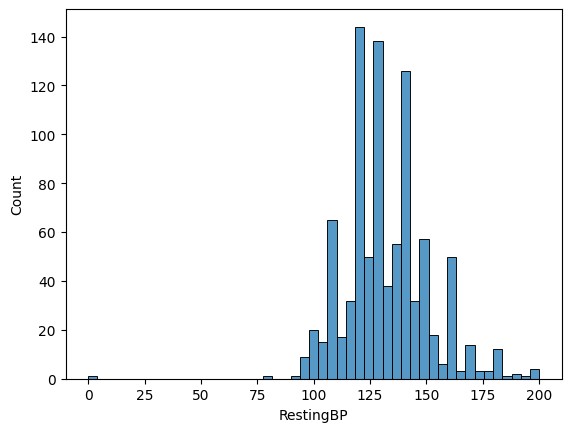

In [35]:
sns.histplot(data = df , x="RestingBP")

<Axes: xlabel='Cholesterol', ylabel='Count'>

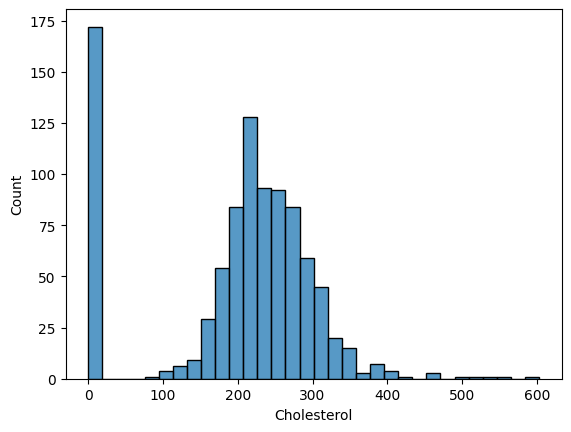

In [36]:
sns.histplot(data = df, x="Cholesterol")

<Axes: xlabel='Oldpeak', ylabel='Count'>

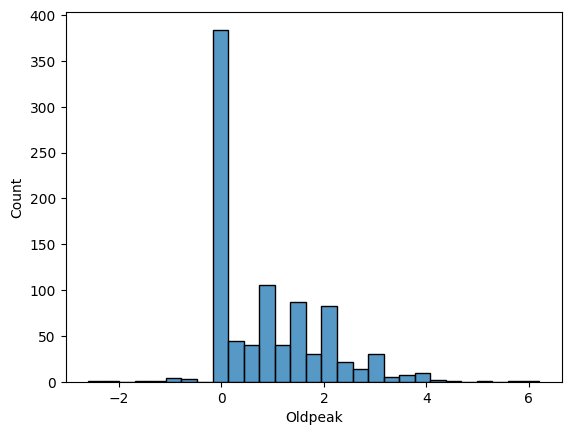

In [37]:
sns.histplot(data = df , x="Oldpeak")

<Axes: ylabel='RestingBP'>

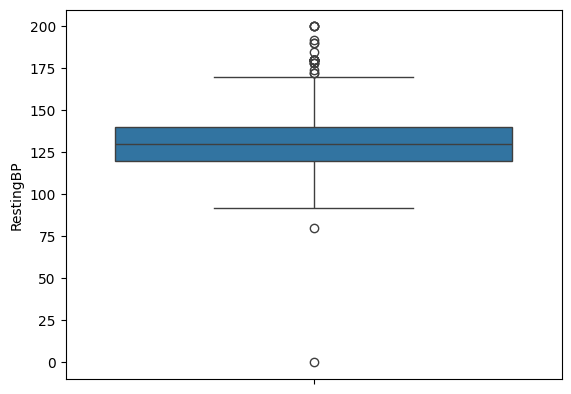

In [ ]:
sns.boxplot(data = df , y="RestingBP")

<Axes: ylabel='Cholesterol'>

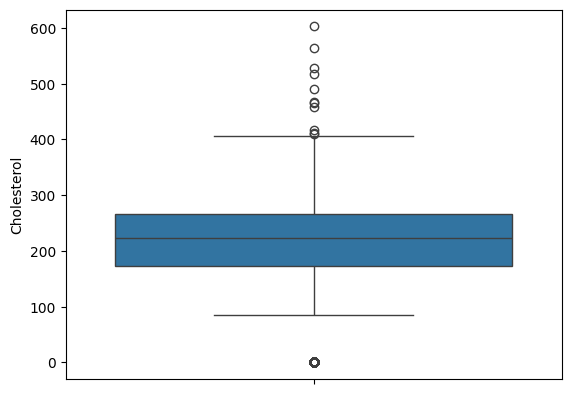

In [40]:
sns.boxplot(data = df , y="Cholesterol")

In [60]:
(data.Cholesterol == 0).sum()/data.shape[0] * 100

np.float64(18.736383442265794)

There are around 19% zero value data in `cholesterol` in data overall. They have to handle properly

`MCAR` : Missing Completely At random missing without affecting influenced from other data.

`MAR` : Missing At random it's missing based on some other data

`MNAR` : Missing Not At random, The missingness occured due to the colun itself

In [62]:
# Visualization 
## Qualitative Impact

import matplotlib.pyplot as plt

data_qual = data.select_dtypes(include=['object']).copy()
len(data_qual.columns)

7

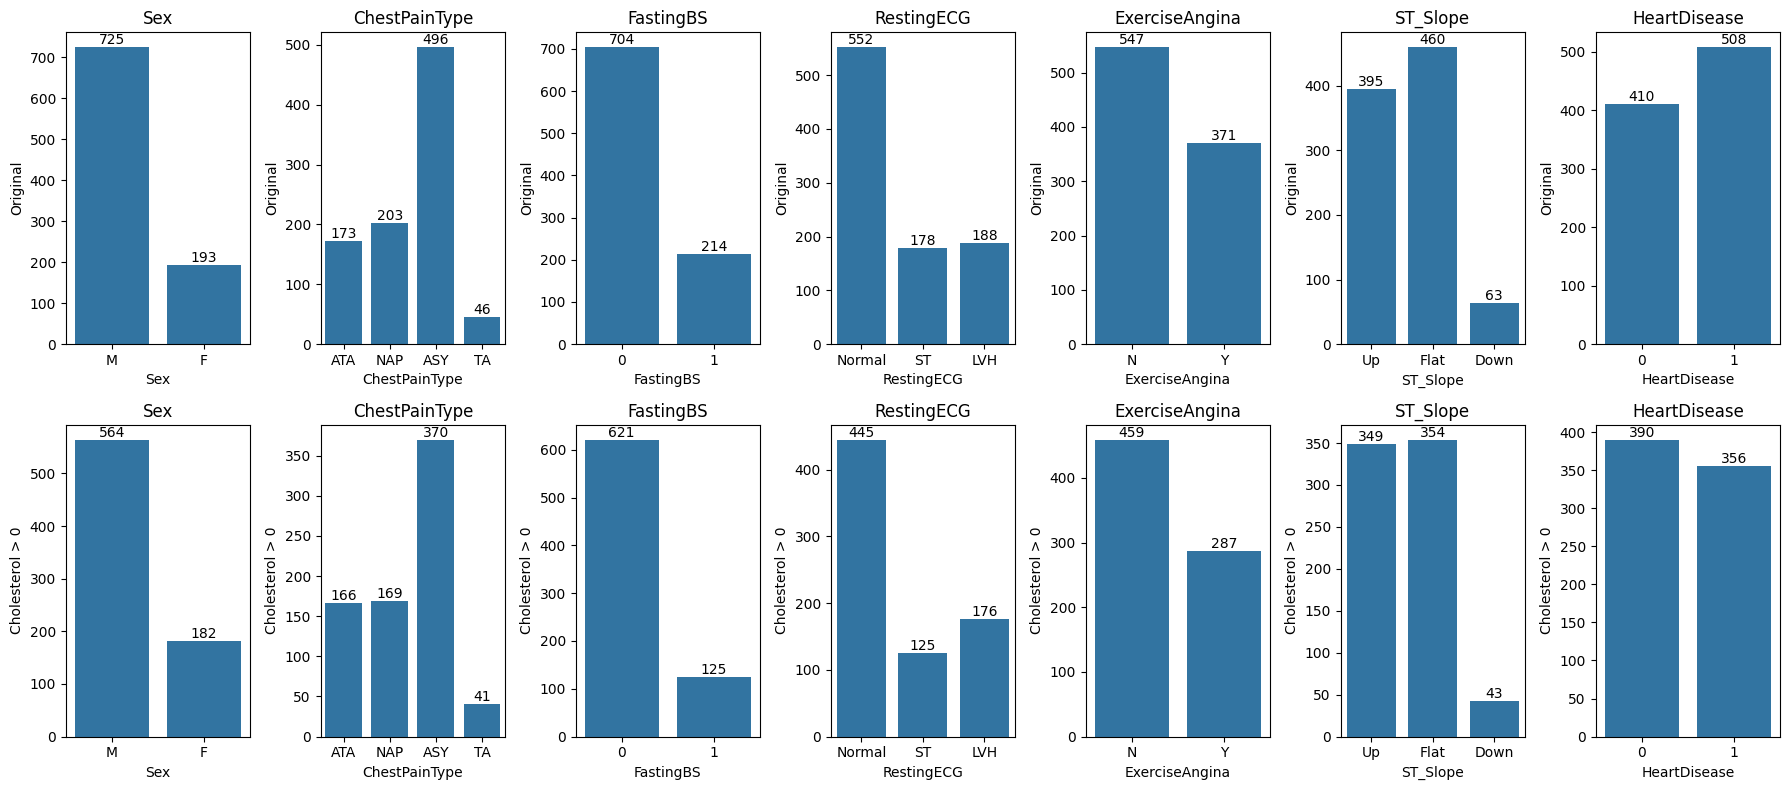

In [94]:
fig, axes = plt.subplots(2, 7, figsize=(18, 8))

data_after = data[data["Cholesterol"] > 0]

for i, col in enumerate(data_qual.columns):

    # Original data
    sns.countplot(data=data, x=col, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel("Original")
    axes[0, i].bar_label(axes[0, i].containers[0], fmt='%d')

    # After removing rows where Cholesterol = 0
    sns.countplot(data=data_after, x=col, ax=axes[1, i])
    axes[1, i].set_title(col)
    axes[1, i].set_ylabel("Cholesterol > 0")
    axes[1, i].bar_label(axes[1, i].containers[0], fmt='%d')

plt.tight_layout()
plt.show()

<Axes: ylabel='Oldpeak'>

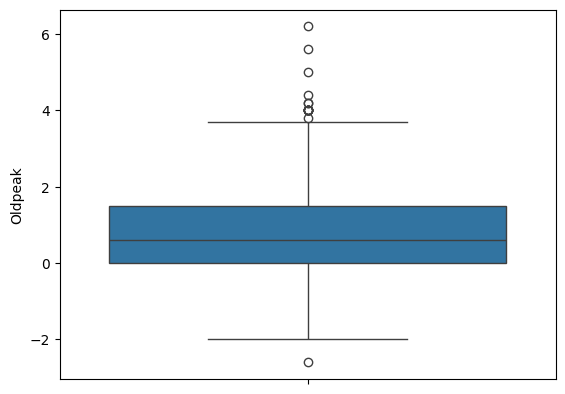

In [41]:
sns.boxplot(data = df , y="Oldpeak")

## Yes there is some outlier in these quantitative data

## 2. Outliers & high leverage data

In an unsupervised framework, outliers are data points that significantly deviate from the majority of observations. In a supervised framework, inputs with extreme values (but not their target) are known as high leverage points. Both outliers and high leverage points may obscure (but not always) the true underlying patterns in the data, often complicating analysis and leading to potential inaccuracies. We will start hunting outliers and high leverage points using [`Abalone` dataset](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset).

**a.** Download and import the dataset.

In [48]:
# To do
df_1 = pd.read_csv("abalone.csv")

In [49]:
df_1.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


**b.** Compute and visualize both correaltion matrices. Provide your first impression on the correlation matrices.

In [57]:
# To do

df_1_number = df_1.select_dtypes(include=['int64', 'float64'])


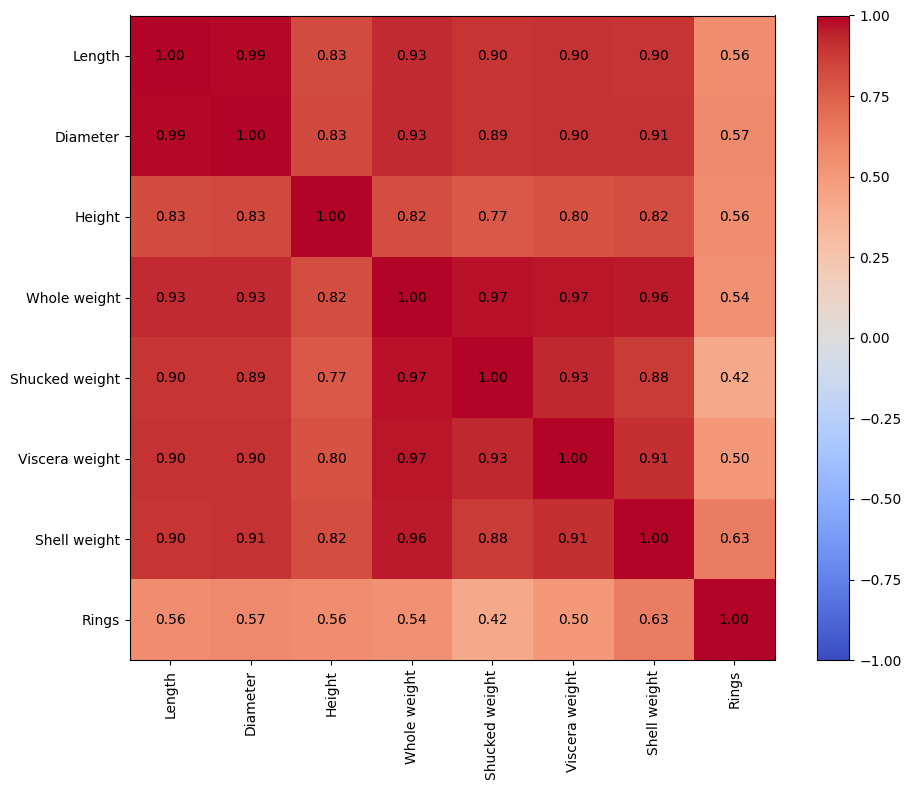

In [58]:
import matplotlib.pyplot as plt

corr = df_1_number.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

# Display correlation values
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}',
                 ha='center', va='center')

plt.tight_layout()
plt.show()

## I can that Ring has low relationship with other

**c.** Study the relation between `Type` and the most interesting variable (target) `Rings`.

In [7]:
# To do

**d.** Insepct outliers and high leverage data points (considering `Rings` as the target) in the dataset. You might be interested in the following interesting lessons from STAT 501:
- [Using Leverages to Help Identify Extreme x Values, STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.2)
- [Identifying Outliers (Unusual y Values), STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.3)

In [8]:
# To do

**e.** Once again, study the correlation matrices of the data after removing outliers and high leverage data points. Conclude.

In [9]:
# To do


# Further Readings

- [Outliers & high leverage observations](https://online.stat.psu.edu/stat501/lesson/11/11.1#:~:text=A%20data%20point%20has%20high,is%20particularly%20high%20or%20low.)
- [Using Leverages to Help Identify Extreme x Values, STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.2)
- [Identifying Outliers (Unusual y Values), STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.3)
- [Missing data: types, explanation, Imputation](https://www.scribbr.com/statistics/missing-data/)
- [Kaggle: Abalone dataset](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset)
- [Chapet 3, section 3.3.3 of The Introduction to Statistical Learning](https://www.stat.berkeley.edu/~rabbee/s154/ISLR_First_Printing.pdf)